<a href="https://colab.research.google.com/github/TheodoraSyntaka/kuramoto-model/blob/main/kuramoto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

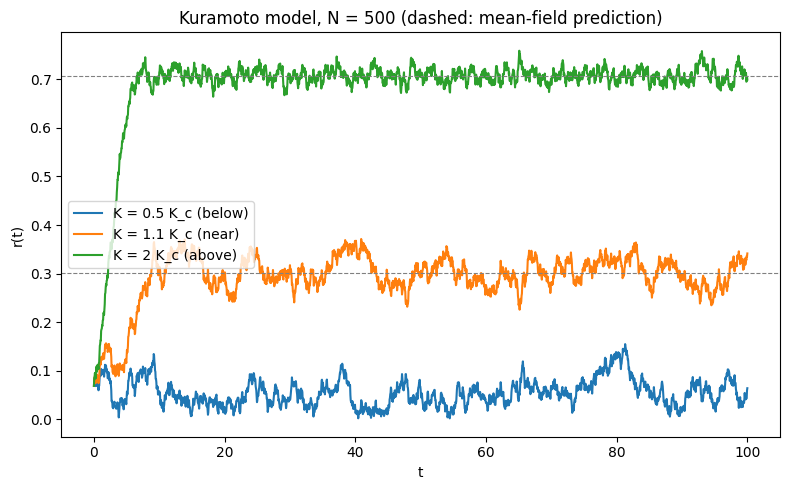

In [1]:
"""
Kuramoto model: particle simulation (steps 1-2 of the project).

dtheta_i/dt = omega_i + (K/N) * sum_j sin(theta_j - theta_i)
            = omega_i + K * r * sin(psi - theta_i)      (mean-field form, O(N) per step)

Natural frequencies follow a Lorentz (Cauchy) distribution with width gamma,
for which theory gives K_c = 2*gamma and r_inf = sqrt(1 - K_c/K) for K > K_c.
"""
import numpy as np
import matplotlib.pyplot as plt


def order_parameter(theta):
    """Return (r, psi) with r*exp(i*psi) = mean(exp(i*theta))."""
    z = np.mean(np.exp(1j * theta))
    return np.abs(z), np.angle(z)


def rhs(theta, omega, K):
    """Right-hand side in mean-field form: O(N) instead of O(N^2)."""
    r, psi = order_parameter(theta)
    return omega + K * r * np.sin(psi - theta)


def rk4_step(theta, omega, K, dt):
    k1 = rhs(theta, omega, K)
    k2 = rhs(theta + 0.5 * dt * k1, omega, K)
    k3 = rhs(theta + 0.5 * dt * k2, omega, K)
    k4 = rhs(theta + dt * k3, omega, K)
    return theta + dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6.0


def lorentz_frequencies(N, gamma):
    """Deterministic quantiles of the Lorentz distribution (less sampling noise)."""
    u = (np.arange(N) + 0.5) / N
    return gamma * np.tan(np.pi * (u - 0.5))


def simulate(N=500, K=2.0, gamma=0.5, T=100.0, dt=0.05, seed=0):
    """Run the simulation; return time array, r(t), and final phases."""
    rng = np.random.default_rng(seed)
    omega = lorentz_frequencies(N, gamma)
    theta = rng.uniform(0, 2 * np.pi, N)  # random initial phases

    steps = int(T / dt)
    t = np.arange(steps + 1) * dt
    r_t = np.empty(steps + 1)
    r_t[0], _ = order_parameter(theta)

    for n in range(steps):
        theta = rk4_step(theta, omega, K, dt)
        r_t[n + 1], _ = order_parameter(theta)

    return t, r_t, theta


if __name__ == "__main__":
    gamma = 0.5
    K_c = 2 * gamma  # theory for the Lorentz distribution

    # Step 2: r(t) below, near, and above the critical coupling
    cases = {"K = 0.5 K_c (below)": 0.5 * K_c,
             "K = 1.1 K_c (near)": 1.1 * K_c,
             "K = 2 K_c (above)": 2.0 * K_c}

    plt.figure(figsize=(8, 5))
    for label, K in cases.items():
        t, r_t, _ = simulate(N=500, K=K, gamma=gamma, T=100.0)
        plt.plot(t, r_t, label=label)
        if K > K_c:
            plt.axhline(np.sqrt(1 - K_c / K), ls="--", lw=0.8, color="gray")

    plt.xlabel("t")
    plt.ylabel("r(t)")
    plt.title("Kuramoto model, N = 500 (dashed: mean-field prediction)")
    plt.legend()
    plt.tight_layout()
    plt.savefig("kuramoto_r_of_t.png", dpi=150)
    plt.show()

    # TODO (step 3): loop over many values of K, average r over the last part
    #   of the run, plot it against K and add the curve sqrt(1 - K_c/K).
    # TODO (step 4): repeat for N = 50, 200, 1000, 5000 and look at how the
    #   fluctuations of r scale with N.

## What does this plot show?

The Kuramoto model describes many oscillators (think of fireflies,
metronomes or neurons), each with its own natural frequency, that
influence each other through a coupling strength K. The question is:
do they synchronise?

The quantity r(t) measures synchronisation. If r is close to 0, the
oscillators are out of phase with each other. If r is close to 1, they
move almost in unison.

The plot shows r(t) for N = 500 oscillators and three coupling
strengths, relative to a critical value K_c predicted by theory:

- **Below K_c (blue):** r stays close to 0. The coupling is too weak
  to overcome the differences in natural frequencies.
- **Slightly above K_c (orange):** r rises to a moderate value of
  about 0.3 and fluctuates strongly.
- **Well above K_c (green):** r quickly rises to about 0.7 and stays
  there. A large fraction of the oscillators is synchronised.

The dashed lines are the theoretical predictions for infinitely many
oscillators, r = sqrt(1 - K_c/K). The simulation follows them closely.
The remaining fluctuations come from having only a finite number of
oscillators, which we study in the next section.

N =    50   mean r = 0.1770   r*sqrt(N) = 1.25
N =   200   mean r = 0.0869   r*sqrt(N) = 1.23
N =  1000   mean r = 0.0391   r*sqrt(N) = 1.24
N =  5000   mean r = 0.0181   r*sqrt(N) = 1.28


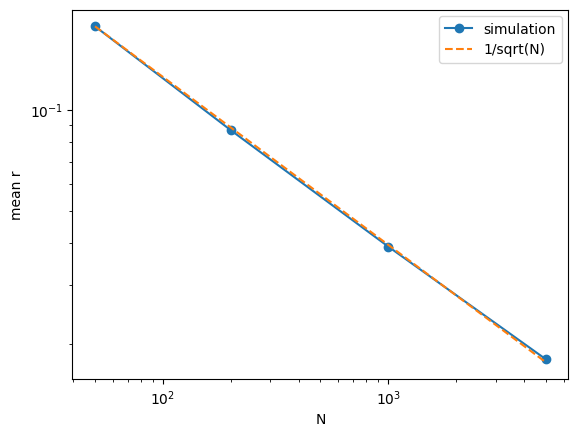

In [2]:
def run_random(N, K, gamma, seed, T=100.0, dt=0.05):
    rng = np.random.default_rng(seed)
    omega = gamma * rng.standard_cauchy(N)      # random Lorentz frequencies
    theta = rng.uniform(0, 2*np.pi, N)
    r_vals = []
    for _ in range(int(T/dt)):
        theta = rk4_step(theta, omega, K, dt)
        r_vals.append(order_parameter(theta)[0])
    return np.mean(r_vals[len(r_vals)//2:])     # average over second half

gamma = 0.5
K = 0.5                                          # below K_c = 1
Ns = [50, 200, 1000, 5000]
means = []
for N in Ns:
    vals = [run_random(N, K, gamma, seed) for seed in range(5)]
    means.append(np.mean(vals))
    print(f"N = {N:5d}   mean r = {means[-1]:.4f}   r*sqrt(N) = {means[-1]*np.sqrt(N):.2f}")

plt.loglog(Ns, means, "o-", label="simulation")
plt.loglog(Ns, [means[0]*np.sqrt(Ns[0]/n) for n in Ns], "--", label="1/sqrt(N)")
plt.xlabel("N"); plt.ylabel("mean r"); plt.legend(); plt.show()

## How does the synchronisation depend on the system size?

Theory predicts that below the critical coupling K_c the oscillators
stay completely unsynchronised, r = 0, but only for an infinite number
of oscillators. In a simulation with a finite number N of oscillators,
r is small but not exactly zero, because random fluctuations in the
phases never cancel perfectly.

This plot shows the average r for K below K_c and for different system
sizes N = 50 to 5000 (log-log scale, averaged over 5 random runs).
The dashed line shows the 1/sqrt(N) scaling.

The simulation follows this line closely: when the system becomes 100
times larger, r becomes about 10 times smaller. This is the same effect
as in the central limit theorem: the average of N independent random
contributions fluctuates with a size of order 1/sqrt(N). It confirms
that the mean-field picture (r = 0 below K_c) becomes exact as N grows.

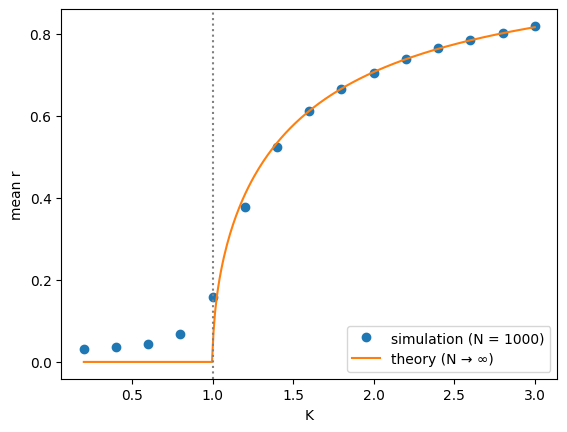

In [3]:
gamma = 0.5
K_c = 2 * gamma
K_values = np.linspace(0.2, 3.0, 15)

r_sim = [np.mean([run_random(1000, K, gamma, seed) for seed in range(3)])
         for K in K_values]

K_th = np.linspace(0.2, 3.0, 300)
r_th = np.sqrt(np.maximum(0.0, 1 - K_c / K_th))     # 0 for K < K_c

plt.plot(K_values, r_sim, "o", label="simulation (N = 1000)")
plt.plot(K_th, r_th, "-", label="theory (N → ∞)")
plt.axvline(K_c, ls=":", color="gray")
plt.xlabel("K"); plt.ylabel("mean r"); plt.legend(); plt.show()

## Phase diagram: when do the oscillators synchronise?

This plot shows the average synchronisation r as a function of the
coupling strength K. Each dot is a simulation with N = 1000
oscillators (averaged over 3 random runs), and the solid line is the
prediction of mean-field theory for infinitely many oscillators:
r = sqrt(1 - K_c/K) for K > K_c, and r = 0 below.

Three things can be seen:
- **For weak coupling (K < K_c)** the oscillators stay unsynchronised.
- **At K_c** a sharp transition occurs: synchronisation appears and
  grows continuously as K increases. This is analogous to a phase
  transition in physics, such as a magnet below its critical
  temperature.
- **For strong coupling** the simulation agrees with the theory very
  well.

Close to K_c the simulation deviates from the theoretical curve and
the transition looks rounded. This is a finite-size effect: with
N = 1000 the fluctuations are still large near the critical point, and
the deviation shrinks when N is increased.

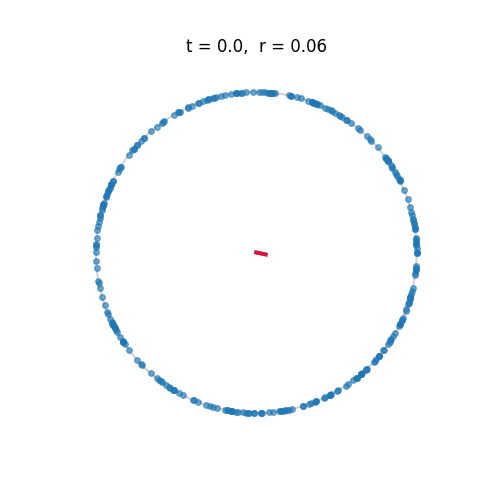

In [6]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

N, K, gamma = 300, 1.5, 0.5
rng = np.random.default_rng(1)
omega = gamma * rng.standard_cauchy(N)
theta = rng.uniform(0, 2*np.pi, N)
dt, steps_per_frame, n_frames = 0.05, 4, 120

frames = []
for _ in range(n_frames):
    for _ in range(steps_per_frame):
        theta = rk4_step(theta, omega, K, dt)
    frames.append(theta.copy())

fig, ax = plt.subplots(figsize=(5, 5))
t_ = np.linspace(0, 2*np.pi, 200)
ax.plot(np.cos(t_), np.sin(t_), color="lightgray")
dots, = ax.plot([], [], "o", ms=4, alpha=0.6)
arrow, = ax.plot([], [], "-", lw=3, color="crimson")
title = ax.set_title("")
ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2)
ax.set_aspect("equal"); ax.axis("off")

def update(i):
    th = frames[i]
    dots.set_data(np.cos(th), np.sin(th))
    r, psi = order_parameter(th)
    arrow.set_data([0, r*np.cos(psi)], [0, r*np.sin(psi)])
    title.set_text(f"t = {i*steps_per_frame*dt:.1f},  r = {r:.2f}")
    return dots, arrow, title

anim = FuncAnimation(fig, update, frames=n_frames, interval=60)
plt.close(fig)
anim.save("kuramoto.gif", writer="pillow", fps=15)   # for the README
from IPython.display import Image
Image("kuramoto.gif")                              # plays it in Colab

## Animation: synchronisation in action

The animation shows N = 300 oscillators. Each dot is one oscillator,
and its position on the circle is its phase, that is, where it is in
its cycle. The red arrow points from the centre to the average
position of all oscillators. Its length is the synchronisation r that
we measured in the plots above, and the title shows its current value.

At the beginning the oscillators are spread randomly around the circle,
so their average is close to the centre and r is small. As time goes
on, the coupling pulls them towards each other. A cluster of
oscillators forms and moves together, and the arrow grows. The
oscillators with natural frequencies far from the average cannot follow
the cluster and keep drifting around the circle, so synchronisation is
partial: r settles at a value below 1.

Here the coupling is K = 1.5, above the critical value K_c = 1. With
a weaker coupling (K = 0.5, below K_c) the cluster never forms and the
arrow stays short, as predicted by the theory in the phase diagram
above.